In [1]:
#1. Import libraries

import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#Load MNIST dataset

mnist = keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [3]:
#Normalize data

x_train = x_train / 255.0
x_test = x_test / 255.0

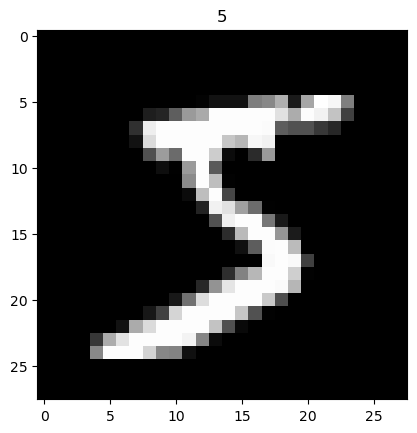

In [4]:
#Display sample image

plt.imshow(x_train[0], cmap='grey')
plt.title(y_train[0])
plt.show()

In [5]:
#Build the model

from tensorflow import keras

model = keras.Sequential([
    keras.Input(shape=(28, 28)),   
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

In [6]:
#Compile the model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [7]:
model.fit(x_train, y_train, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 6ms/step - accuracy: 0.9298 - loss: 0.2425
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9687 - loss: 0.1034
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9777 - loss: 0.0711
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9831 - loss: 0.0530
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9867 - loss: 0.0410


In [8]:

loss, accuracy = model.evaluate(x_test, y_test)
print("Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9764 - loss: 0.0810
Accuracy: 0.9764000177383423


In [9]:
#Make predictions

predictions = model.predict(x_test)

print("Predicted:", np.argmax(predictions[0]))
print("Actual:", y_test[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Predicted: 7
Actual: 7


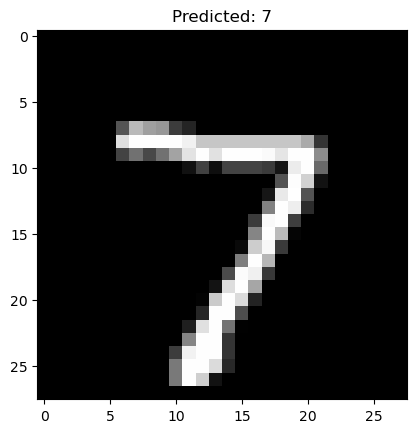

In [10]:
plt.imshow(x_test[0], cmap='grey')
plt.title(f"Predicted: {np.argmax(predictions[0])}")
plt.show()

In [11]:
model.save("digit_model.keras")

In [12]:
#Load model

from tensorflow import keras

model = keras.models.load_model("digit_model.keras")

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


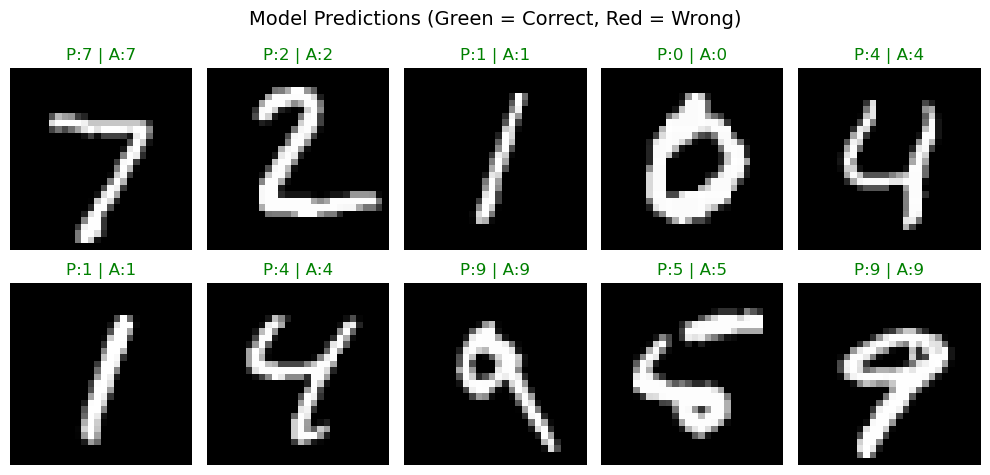

In [13]:
import numpy as np
import matplotlib.pyplot as plt

predictions = model.predict(x_test)

plt.figure(figsize=(10,5))

for i in range(10):
    plt.subplot(2,5,i+1)
    
    img = x_test[i]
    pred = np.argmax(predictions[i])
    actual = y_test[i]
    
    plt.imshow(img, cmap='gray')
    
    # Color: green if correct, red if wrong
    if pred == actual:
        color = 'green'
    else:
        color = 'red'
    
    plt.title(f"P:{pred} | A:{actual}", color=color)
    plt.axis('off')

plt.suptitle("Model Predictions (Green = Correct, Red = Wrong)", fontsize=14)
plt.tight_layout()
plt.show()

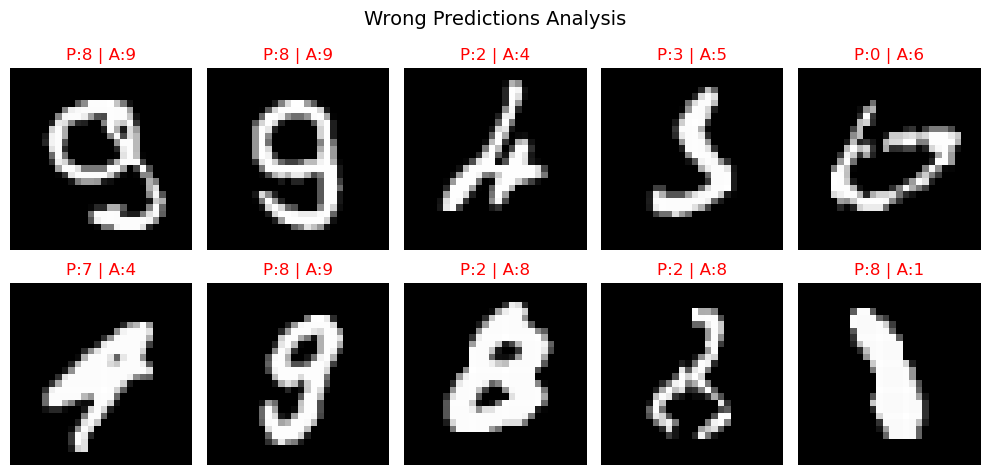

In [14]:

wrong = []

for i in range(len(x_test)):
    if np.argmax(predictions[i]) != y_test[i]:
        wrong.append(i)

plt.figure(figsize=(10,5))

for i in range(10):
    index = wrong[i]
    
    plt.subplot(2,5,i+1)
    plt.imshow(x_test[index], cmap='gray')
    
    pred = np.argmax(predictions[index])
    actual = y_test[index]
    
    plt.title(f"P:{pred} | A:{actual}", color='red')
    plt.axis('off')

plt.suptitle("Wrong Predictions Analysis", fontsize=14)
plt.tight_layout()
plt.show()

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9881 - loss: 0.0373 - val_accuracy: 0.9887 - val_loss: 0.0330
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9910 - loss: 0.0269 - val_accuracy: 0.9890 - val_loss: 0.0348
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9925 - loss: 0.0220 - val_accuracy: 0.9873 - val_loss: 0.0410
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9937 - loss: 0.0188 - val_accuracy: 0.9882 - val_loss: 0.0435
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9932 - loss: 0.0200 - val_accuracy: 0.9847 - val_loss: 0.0540


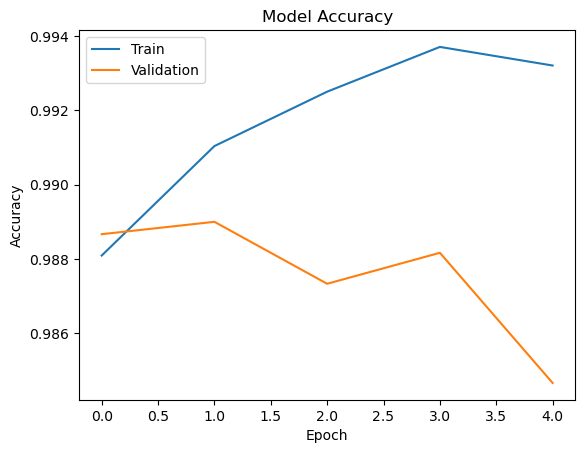

In [15]:
#Accuracy graph

history = model.fit(x_train, y_train, epochs=5, validation_split=0.1)

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])
plt.show()

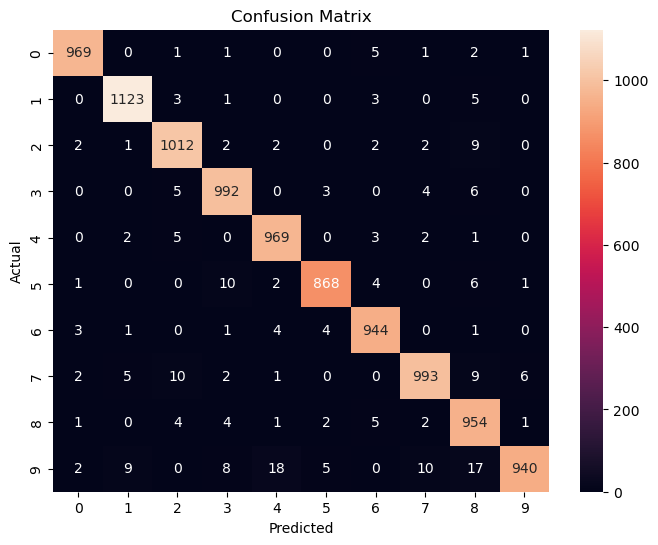

In [16]:
#Confusion matrix,Helps understand which digits are confused

from sklearn.metrics import confusion_matrix
import seaborn as sns

y_pred = np.argmax(predictions, axis=1)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [17]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.98      0.99      0.99      1135
           2       0.97      0.98      0.98      1032
           3       0.97      0.98      0.98      1010
           4       0.97      0.99      0.98       982
           5       0.98      0.97      0.98       892
           6       0.98      0.99      0.98       958
           7       0.98      0.97      0.97      1028
           8       0.94      0.98      0.96       974
           9       0.99      0.93      0.96      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



In [18]:
history = model.fit(x_train, y_train, epochs=5, validation_split=0.1)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9942 - loss: 0.0164 - val_accuracy: 0.9830 - val_loss: 0.0670
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9951 - loss: 0.0146 - val_accuracy: 0.9837 - val_loss: 0.0627
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9949 - loss: 0.0138 - val_accuracy: 0.9855 - val_loss: 0.0609
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9963 - loss: 0.0101 - val_accuracy: 0.9843 - val_loss: 0.0753
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9955 - loss: 0.0140 - val_accuracy: 0.9853 - val_loss: 0.0663


In [19]:
print("Train Accuracy:", history.history['accuracy'][-1])
print("Validation Accuracy:", history.history['val_accuracy'][-1])

Train Accuracy: 0.9955370426177979
Validation Accuracy: 0.9853333234786987


In [20]:
loss, test_accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9803 - loss: 0.0912
Test Accuracy: 0.9803000092506409


In [ ]:
!pip install pygame

In [ ]:
import pygame
import numpy as np
import tensorflow as tf
from scipy.ndimage import center_of_mass

# load model
model = tf.keras.models.load_model("digit_model.keras")

pygame.init()
screen = pygame.display.set_mode((280, 280))
pygame.display.set_caption("Draw a Digit (ENTER=predict, C=clear)")
font = pygame.font.SysFont("Arial", 24)

def preprocess(surface):
    # Step 1: Grab and grayscale
    data = pygame.surfarray.array3d(surface)
    gray = np.mean(data, axis=2).T  # shape (280, 280)

    # Step 2: Crop to bounding box of drawn digit
    rows = np.any(gray > 10, axis=1)
    cols = np.any(gray > 10, axis=0)
    if not rows.any():
        return None
    rmin, rmax = np.where(rows)[0][[0, -1]]
    cmin, cmax = np.where(cols)[0][[0, -1]]

    cropped = gray[rmin:rmax+1, cmin:cmax+1]

    # Step 3: Add padding so digit isn't touching edges
    pad = 30
    cropped = np.pad(cropped, pad, mode='constant', constant_values=0)

    # Step 4: Resize to 28x28 using pygame (clean interpolation)
    h, w = cropped.shape
    rgb = np.stack([cropped]*3, axis=-1).astype(np.uint8)
    surf = pygame.surfarray.make_surface(rgb.transpose(1, 0, 2))
    scaled = pygame.transform.smoothscale(surf, (20, 20))  # 20x20 then center in 28x28
    small = np.mean(pygame.surfarray.array3d(scaled), axis=2).T

    # Step 5: Center in 28x28 canvas (MNIST style)
    canvas = np.zeros((28, 28))
    canvas[4:24, 4:24] = small / 255.0

    # Step 6: Center of mass shift (MNIST preprocessing trick)
    cy, cx = center_of_mass(canvas)
    dy = int(14 - cy)
    dx = int(14 - cx)
    canvas = np.roll(canvas, dy, axis=0)
    canvas = np.roll(canvas, dx, axis=1)

    return canvas

prediction_text = ""

running = True
while running:
    for event in pygame.event.get():
        if event.type == pygame.QUIT:
            running = False

        if event.type == pygame.KEYDOWN:
            # ENTER to predict
            if event.key == pygame.K_RETURN:
                canvas = preprocess(screen)
                if canvas is not None:
                    inp = canvas.reshape(1, 28, 28, 1).astype(np.float32)
                    prediction = model.predict(inp, verbose=0)
                    digit = np.argmax(prediction)
                    confidence = np.max(prediction) * 100
                    prediction_text = f"Digit: {digit}  ({confidence:.1f}%)"
                    print(prediction_text)
                else:
                    print("Nothing drawn!")

            # C to clear
            if event.key == pygame.K_c:
                screen.fill((0, 0, 0))
                prediction_text = ""
                pygame.display.flip()

    # Draw with mouse - bigger brush for cleaner input
    if pygame.mouse.get_pressed()[0]:
        pos = pygame.mouse.get_pos()
        pygame.draw.circle(screen, (255, 255, 255), pos, 12)  # radius 12

    # Show prediction on screen
    screen.blit(
        font.render(prediction_text, True, (0, 255, 0)),
        (5, 5)
    )

    pygame.display.flip()

pygame.quit()